In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, roc_auc_score

In [ ]:
df = pd.read_csv('/content/titanic_data.csv')
print("Dataset Loaded Succefully")

Dataset Loaded Succefully


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe

<bound method NDFrame.describe of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ...    ...   
886                              Montvila, Rev. Juozas    male  27.0      0   
887                       Graham, Miss. Margaret Edith  female  19.0      0   
888           Johnston, Miss. Catherine Helen "Carrie"  female   NaN      1   
889                              Behr, Mr. Karl Howell    male  26.0      0   
890                                Dooley, Mr. Patrick    male  32.0      0   

     Parch            Ticket     Fare Cabin Embarked  
0        0         A/5 21171   7.2500   NaN        S  
1        0          PC 17599  71.2833   C85        C  
2        0  STON/O2. 3101282   7.9250   NaN        S  
3        0            113803  53.1000  C123        S  
4        0            373450   8.0500   NaN        S  
..     ...               ...      ...   ...      ...  
886      0            211536  13.0000   NaN        S  
887      0            112053  30.0000   B42        S  
888      2        W./C. 6607  23.4500   NaN        S  
889      0            111369  30.0000  C148        C  
890      0            370376   7.7500   NaN        Q  

[891 rows x 12 columns]>

In [ ]:
df.shape

(891, 12)

In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print("No of Duplicate records:",df.duplicated().sum())

No of Duplicate records: 0


In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
# fill the missing values
df['Age'].fillna(df['Age'].mean(), inplace=True)
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)

/tmp/ipykernel_2305/3160187473.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace=True)


In [ ]:
# Drop the column Cabin
df.drop('Cabin', axis=1, inplace=True)

KeyError: "['Cabin'] not found in axis"

In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
# LabelEncoder
le = LabelEncoder()
df['Sex'] = le.fit_transform(df['Sex'])

In [ ]:
# OnehotEncoding
df = pd.get_dummies(df, columns=['Embarked'])

In [ ]:
# Drop the coulms Name and Ticket
df.drop(['Name', 'Ticket'], axis=1, inplace=True)

In [ ]:
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,1,22.0,1,0,7.2500,False,False,True
1,2,1,1,0,38.0,1,0,71.2833,True,False,False
2,3,1,3,0,26.0,0,0,7.9250,False,False,True
3,4,1,1,0,35.0,1,0,53.1000,False,False,True
4,5,0,3,1,35.0,0,0,8.0500,False,False,True


In [ ]:
df['FamilySize'] = df['SibSp'] + df['Parch']+1
print(df[['SibSp','Parch','FamilySize']].head())

   SibSp  Parch  FamilySize
0      1      0           2
1      1      0           2
2      0      0           1
3      1      0           2
4      0      0           1


In [ ]:
# outlier detection
q1 = df['Age'].quantile(0.25)
q3 = df['Age'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5*iqr
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Lower Bound: 2.5
Upper Bound: 54.5


In [ ]:
# Print outliers
outliers = df[(df['Age'] < lower_bound) | (df['Age'] > upper_bound)]
print("Outliers:")
print(outliers)

Outliers:
     PassengerId  Survived  Pclass  Sex    Age  SibSp  Parch     Fare  \
7              8         0       3    1   2.00      3      1  21.0750   
11            12         1       1    0  58.00      0      0  26.5500   
15            16         1       2    0  55.00      0      0  16.0000   
16            17         0       3    1   2.00      4      1  29.1250   
33            34         0       2    1  66.00      0      0  10.5000   
..           ...       ...     ...  ...    ...    ...    ...      ...   
827          828         1       2    1   1.00      0      2  37.0042   
829          830         1       1    0  62.00      0      0  80.0000   
831          832         1       2    1   0.83      1      1  18.7500   
851          852         0       3    1  74.00      0      0   7.7750   
879          880         1       1    0  56.00      0      1  83.1583   

     Embarked_C  Embarked_Q  Embarked_S  FamilySize  
7         False       False        True           5  
11   

In [ ]:
# Remove outliers
df = df[(df['Age'] >= lower_bound) & (df['Age'] <= upper_bound)]
print("After Removing outliers:")
print(df)

After Removing outliers:
     PassengerId  Survived  Pclass  Sex        Age  SibSp  Parch     Fare  \
0              1         0       3    1  22.000000      1      0   7.2500   
1              2         1       1    0  38.000000      1      0  71.2833   
2              3         1       3    0  26.000000      0      0   7.9250   
3              4         1       1    0  35.000000      1      0  53.1000   
4              5         0       3    1  35.000000      0      0   8.0500   
..           ...       ...     ...  ...        ...    ...    ...      ...   
886          887         0       2    1  27.000000      0      0  13.0000   
887          888         1       1    0  19.000000      0      0  30.0000   
888          889         0       3    0  29.699118      1      2  23.4500   
889          890         1       1    1  26.000000      0      0  30.0000   
890          891         0       3    1  32.000000      0      0   7.7500   

     Embarked_C  Embarked_Q  Embarked_S  FamilySiz

In [ ]:
# outlier detection for Fare
q1 = df['Fare'].quantile(0.25)
q3 = df['Fare'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q1 + 1.5 * iqr
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Lower Bound: -25.366699999999994
Upper Bound: 41.1583


In [ ]:
# Remove outliers
df = df[(df['Fare'] >= lower_bound) & (df['Fare'] <= upper_bound)]
print("After Removing outliers:")
print(df)

After Removing outliers:
     PassengerId  Survived  Pclass  Sex        Age  SibSp  Parch     Fare  \
0              1         0       3    1  22.000000      1      0   7.2500   
2              3         1       3    0  26.000000      0      0   7.9250   
4              5         0       3    1  35.000000      0      0   8.0500   
5              6         0       3    1  29.699118      0      0   8.4583   
8              9         1       3    0  27.000000      0      2  11.1333   
..           ...       ...     ...  ...        ...    ...    ...      ...   
886          887         0       2    1  27.000000      0      0  13.0000   
887          888         1       1    0  19.000000      0      0  30.0000   
888          889         0       3    0  29.699118      1      2  23.4500   
889          890         1       1    1  26.000000      0      0  30.0000   
890          891         0       3    1  32.000000      0      0   7.7500   

     Embarked_C  Embarked_Q  Embarked_S  FamilySiz

In [ ]:
x = df.drop(['PassengerId','Survived'], axis=1)
y = df['Survived']

In [ ]:
#split the dataset into training and testing
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
cols_to_scale = ['Age','SibSp','Fare','FamilySize']
x_train[cols_to_scale] = scaler.fit_transform(x_train[cols_to_scale])
x_test[cols_to_scale] = scaler.transform(x_test[cols_to_scale])
print("first 5 rows of x_train:")
print(x_train.head())

first 5 rows of x_train:
     Pclass  Sex       Age     SibSp  Parch      Fare  Embarked_C  Embarked_Q  \
25        3    0  0.940609  0.759032      5  1.863455       False       False   
701       1    1  0.639010 -0.464620      0  1.296573       False       False   
746       3    1 -1.271118  0.759032      1  0.625484       False       False   
618       2    0 -2.477514  1.982683      1  2.709610       False       False   
84        2    0 -1.170585 -0.464620      0 -0.458261       False       False   

     Embarked_S  FamilySize  
25         True    4.046520  
701        True   -0.515999  
746        True    1.004841  
618        True    1.765260  
84         True   -0.515999  


In [ ]:
#model building
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [ ]:
# prediction on test data
y_pred = model.predict(x_test)

In [ ]:
train_accuracy = model.score(x_train, y_train)
test_accuracy = model.score(x_test, y_test)
print("Train Accuracy:",train_accuracy)
print("Test Accuracy:",test_accuracy)

Train Accuracy: 0.33528806612861195
Test Accuracy: 0.32524639835829383


In [ ]:
# confusion metrics
cont_matrix = pd.crosstab(y_test, y_pred.round(), rownames=['Actual'], colnames=['Predicted'])
print("Confusion Matrix:")
print(cont_matrix)

Confusion Matrix:
Predicted  0.0  1.0
Actual             
0           80   15
1           11   27


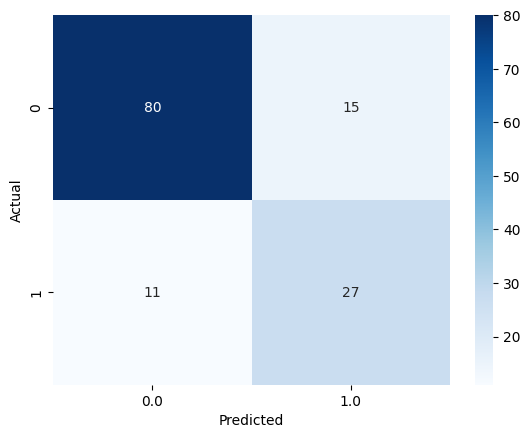

In [ ]:
# Display cont_matrix with xlable and y label
sns.heatmap(cont_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
# print classification report
class_report = classification_report(y_test, y_pred.round())
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.84      0.86        95
           1       0.64      0.71      0.68        38

    accuracy                           0.80       133
   macro avg       0.76      0.78      0.77       133
weighted avg       0.81      0.80      0.81       133



In [ ]:
#auc_roc_curve and auc_curve
fpr,tpr,thresholds = roc_curve(y_test,y_pred)
auc_roc = roc_auc_score(y_test,y_pred)
print("AUC-ROC:",auc_roc)

AUC-ROC: 0.8175900277008309


Text(0, 0.5, 'True Positive Rate')

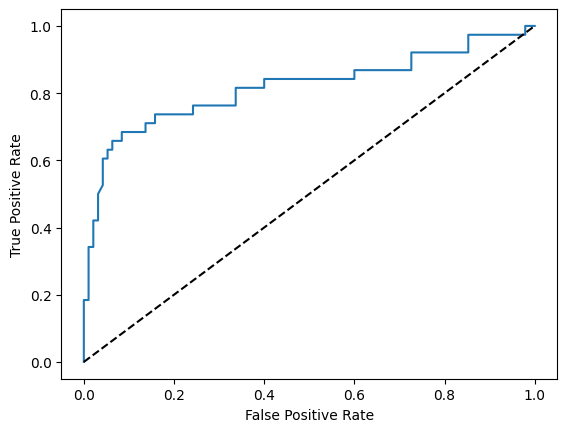

In [ ]:
# display auc_roc_curve
#display auc_roc_curve
plt.plot(fpr,tpr,label='AUC-ROC={:.2f}'.format(auc_roc))
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

In [ ]:
# prediction on test data
y_pred = model.predict(x_test)

train_accuracy = model.score(x_train, y_train)
test_accuracy = model.score(x_test, y_test)
print("Train Accuracy:",train_accuracy)
print("Test Accuracy:",test_accuracy)

# confusion metrics
cont_matrix = pd.crosstab(y_test, y_pred.round(), rownames=['Actual'], colnames=['Predicted'])
print("Confusion Matrix:")
print(cont_matrix)

# Display cont_matrix with xlable and y label
sns.heatmap(cont_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# print classification report
class_report = classification_report(y_test, y_pred.round())
print("Classification Report:")
print(class_report)

#auc_roc_curve and auc_curve
fpr,tpr,thresholds = roc_curve(y_test,y_pred)
auc_roc = roc_auc_score(y_test,y_pred)
print("AUC-ROC:",auc_roc)

# display auc_roc_curve
#display auc_roc_curve
plt.plot(fpr,tpr,label='AUC-ROC={:.2f}'.format(auc_roc))
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')